# 2. Pipeline do trenowania modelu - szacowanie czasu półmaratonu

Kroki pipeline'u:
1. czytam dane z Digital Ocean Spaces (lekcja `10__cloud_storage.ipynb`),
2. czyszczę je (snippet z `41__zadanie_domowe.ipynb`, lekcje `12__handling_missing_data.ipynb` i `18__data_preparation__outliers.ipynb`),
3. dobieram cechy (lekcja `20__data_preparation__feature_selection.ipynb`),
4. trenuję model regresji w PyCaret (lekcje `24__in_search_of_the_best_model__pycaret_flow.ipynb` i `29__model_monitoring__mlflow_pycaret.ipynb`),
5. zapisuję nową wersję modelu lokalnie i do Digital Ocean Spaces.

In [1]:
#!pip install --quiet pycaret boto3 s3fs python-dotenv

In [2]:
import json
import shutil
from datetime import datetime
from pathlib import Path

import boto3
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from pycaret.regression import setup

load_dotenv()

True

In [3]:
BUCKET_NAME = "jerry-77"
DATA_PREFIX = "polmaraton/data/"
MODELS_PREFIX = "polmaraton/models/"
LOCAL_MODELS_PATH = Path("models")

# Zbiór ma 2 pliki - używam obu, bo mają identyczną strukturę, a więcej danych to lepszy model
YEARS = [2023, 2024]

## 2.1 Czytam dane z Digital Ocean Spaces

Tak jak w lekcji 10 czytam CSV prosto z bucketa przez `pd.read_csv("s3://...")` (pod spodem działa `s3fs`).
Do każdego pliku dokładam kolumnę `Rok`, żeby po połączeniu wiedzieć, z którego biegu jest wynik.

In [4]:
dfs = []
for year in YEARS:
    df_year = pd.read_csv(f"s3://{BUCKET_NAME}/{DATA_PREFIX}halfmarathon_wroclaw_{year}__final.csv", sep=";")
    df_year["Rok"] = year
    print(year, df_year.shape)
    dfs.append(df_year)

raw_df = pd.concat(dfs, ignore_index=True)
raw_df.head()

2023 (8950, 28)
2024 (13007, 28)


,Miejsce,Numer startowy,Imię,Nazwisko,Miasto,Kraj,Drużyna,Płeć,Płeć Miejsce,Kategoria wiekowa,...,15 km Czas,15 km Miejsce Open,15 km Tempo,20 km Czas,20 km Miejsce Open,20 km Tempo,Tempo Stabilność,Czas,Tempo,Rok
0,1.0,1787,TOMASZ,GRYCKO,NaN,POL,UKS BLIZA WŁADYSŁAWOWO,M,1.0,M30,...,00:44:47,1.0,3.106667,01:01:43,1.0,3.386667,0.031400,01:04:59,3.080509,2023
1,2.0,3,ARKADIUSZ,GARDZIELEWSKI,WROCŁAW,POL,ARKADIUSZGARDZIELEWSKI.PL,M,2.0,M30,...,00:45:26,2.0,3.143333,01:03:08,2.0,3.540000,0.038000,01:06:23,3.146875,2023
2,3.0,3832,KRZYSZTOF,HADAS,POZNAŃ,POL,NaN,M,3.0,M20,...,00:47:34,3.0,3.236667,01:05:09,3.0,3.516667,0.024067,01:08:24,3.242475,2023
3,4.0,416,DAMIAN,DYDUCH,KĘPNO,POL,AZS POLITECHNIKA OPOLSKA,M,4.0,M30,...,00:48:49,5.0,3.330000,01:06:54,4.0,3.616667,0.025467,01:10:16,3.330963,2023
4,5.0,8476,KAMIL,MAŃKOWSKI,MIRKÓW,POL,PARKRUN WROCŁAW,M,5.0,M20,...,00:49:31,7.0,3.386667,01:07:27,5.0,3.586667,0.023000,01:10:27,3.339654,2023


In [5]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21957 entries, 0 to 21956
Data columns (total 28 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Miejsce                    18450 non-null  float64
 1   Numer startowy             21957 non-null  int64  
 2   Imię                       21957 non-null  object 
 3   Nazwisko                   21957 non-null  object 
 4   Miasto                     17774 non-null  object 
 5   Kraj                       18450 non-null  object 
 6   Drużyna                    8402 non-null   object 
 7   Płeć                       21946 non-null  object 
 8   Płeć Miejsce               18450 non-null  float64
 9   Kategoria wiekowa          21926 non-null  object 
 10  Kategoria wiekowa Miejsce  18430 non-null  float64
 11  Rocznik                    21472 non-null  float64
 12  5 km Czas                  18411 non-null  object 
 13  5 km Miejsce Open          18411 non-null  flo

## 2.2 Czyszczę dane

In [6]:
# Snippet pomocniczy z 41__zadanie_domowe.ipynb - zmiana czasu na sekundy
def convert_time_to_seconds(time):
    if pd.isnull(time) or time in ['DNS', 'DNF']:
        return None
    time = time.split(':')
    return int(time[0]) * 3600 + int(time[1]) * 60 + int(time[2])

In [7]:
df = raw_df.copy()

for col in ["5 km Czas", "10 km Czas", "15 km Czas", "20 km Czas", "Czas"]:
    df[col] = df[col].apply(convert_time_to_seconds)

# Dodatek: wiek liczę względem roku biegu, a nie samego rocznika,
# dzięki temu 30-latek z 2023 i 30-latek z 2024 mają ten sam wiek
df["Wiek"] = df["Rok"] - df["Rocznik"]

# Ile brakuje danych w kolumnach, które mnie interesują (podejście z lekcji 12)
df[["Płeć", "Rocznik", "5 km Czas", "10 km Czas", "15 km Czas", "Czas"]].isnull().sum()

Płeć            11
Rocznik        485
5 km Czas     3546
10 km Czas    3530
15 km Czas    3529
Czas          3507
dtype: int64

In [8]:
# Braki w celu (Czas = DNS/DNF/NaN) i w cechach usuwam - nie da się ich sensownie uzupełnić.
# Rocznik = 0 to błąd w danych, więc też go odrzucam.
df = df.dropna(subset=["Płeć", "Rocznik", "5 km Czas", "Czas"])
df = df[(df["Rocznik"] > 0) & (df["5 km Czas"] > 0)]

print("Po usunięciu braków:", df.shape)

Po usunięciu braków: (17908, 29)


In [9]:
# Dodatek: zmieniam nazwy kolumn na proste, bez polskich znaków i spacji -
# takie same nazwy wpisuję potem w app.py
df = df.rename(columns={
    "Płeć": "plec",
    "Wiek": "wiek",
    "5 km Czas": "czas_5km",
    "10 km Czas": "czas_10km",
    "15 km Czas": "czas_15km",
    "Czas": "czas",
    "Rok": "rok",
})
df = df[["rok", "plec", "wiek", "czas_5km", "czas_10km", "czas_15km", "czas"]]
df.describe().T

,count,mean,std,min,25%,50%,75%,max
rok,17908.0,2023.558075,0.496630,2023.0,2023.00,2024.0,2024.00,2024.0
wiek,17908.0,39.181986,10.232059,17.0,32.00,39.0,46.00,89.0
czas_5km,17908.0,1672.380333,246.453360,877.0,1500.75,1660.0,1833.00,3825.0
czas_10km,17893.0,3339.848041,508.475930,1755.0,2981.00,3307.0,3658.00,5899.0
czas_15km,17894.0,5105.937353,800.485525,2687.0,4540.00,5039.0,5597.00,8763.0
czas,17908.0,7391.771945,1211.286563,3843.0,6544.00,7240.0,8127.25,12512.0


### Outliery

Przy równym tempie czas półmaratonu powinien być ok. 4,2 raza dłuższy niż czas na 5 km (21,1 km / 5 km).
Wyniki, które mocno od tego odbiegają, to najczęściej błędy pomiaru - widać je na wykresie poniżej.
Żeby je znaleźć, liczę stosunek `czas / czas_5km`
i usuwam wartości odstające metodą IQR z lekcji `18__data_preparation__outliers.ipynb`.

*Dodatek: w lekcji IQR był liczony na samej zmiennej, tu liczę go na stosunku dwóch czasów, żeby wyłapać błędy pomiaru, a nie wolnych biegaczy.*

In [10]:
ratio = df["czas"] / df["czas_5km"]

Q1 = ratio.quantile(0.25)
Q3 = ratio.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print(f"Granice: {lower_bound:.2f} - {upper_bound:.2f}")

clean_df = df[~((ratio < lower_bound) | (ratio > upper_bound))]
print("Usunięte outliery:", len(df) - len(clean_df))
print("Po czyszczeniu:", clean_df.shape)

Granice: 3.85 - 4.94
Usunięte outliery: 617
Po czyszczeniu: (17291, 7)


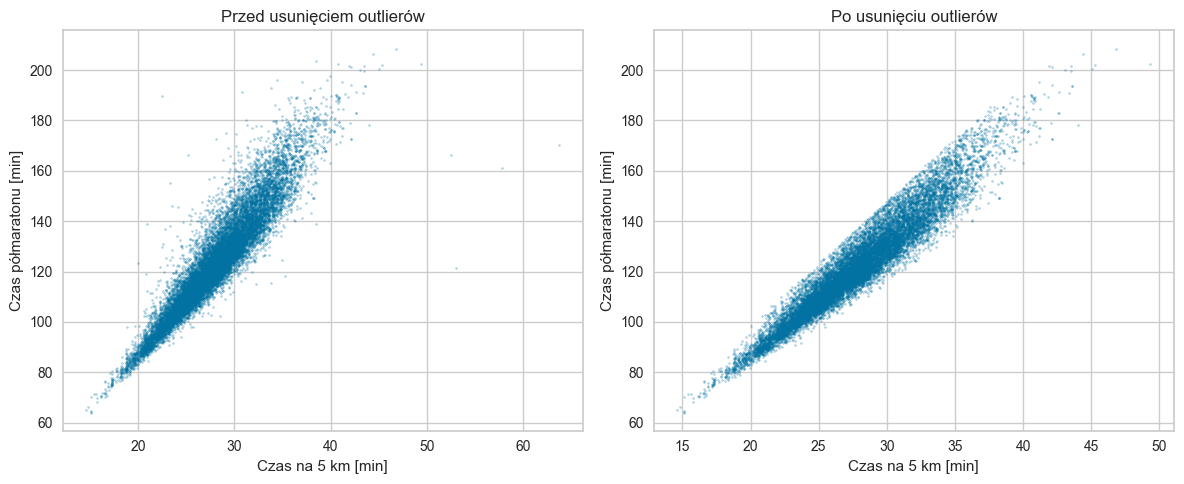

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(df["czas_5km"] / 60, df["czas"] / 60, s=2, alpha=0.3)
axes[0].set_title("Przed usunięciem outlierów")
axes[1].scatter(clean_df["czas_5km"] / 60, clean_df["czas"] / 60, s=2, alpha=0.3)
axes[1].set_title("Po usunięciu outlierów")
for ax in axes:
    ax.set_xlabel("Czas na 5 km [min]")
    ax.set_ylabel("Czas półmaratonu [min]")
plt.tight_layout()
plt.show()

## 2.3 Dobór cech (feature selection)

Tak jak w lekcji 20 sprawdzam najpierw, jak ważne są poszczególne cechy, gdy dam modelowi więcej informacji
(także czasy na 10 i 15 km). Potem zostawiam tylko te cechy, które użytkownik może podać w aplikacji:
**płeć, wiek i czas na 5 km**. Pozostałe wyłączam przez `ignore_features` (podejście z lekcji 20).

Jako metrykę główną biorę **MAE** - to średni błąd w sekundach, łatwo go zrozumieć
("model myli się średnio o X minut"). Patrzę też na **RMSE** i **R2**.

In [12]:
# Eksperyment A - wszystkie cechy (rok wyłączam, bo użytkownik go nie podaje i nie ma wpływu na wynik biegacza)
exp_all = setup(
    data=clean_df,
    target="czas",
    ignore_features=["rok"],
    session_id=123,
    verbose=False,
)
lgbm_all = exp_all.create_model("lightgbm", verbose=False)
exp_all.pull()

,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,85.6791,14929.5595,122.1866,0.9883,0.0160,0.0115
1,85.7034,15731.1135,125.4237,0.9885,0.0160,0.0115
2,85.1114,28815.3985,169.7510,0.9761,0.0200,0.0113
3,90.8681,18201.7013,134.9137,0.9867,0.0177,0.0121
4,85.9488,15060.8469,122.7226,0.9901,0.0160,0.0115
5,89.0855,16894.3444,129.9782,0.9876,0.0166,0.0118
6,87.0646,15236.1849,123.4349,0.9892,0.0160,0.0116
7,84.7550,15062.0440,122.7275,0.9891,0.0160,0.0114
8,88.7333,23355.2110,152.8241,0.9834,0.0189,0.0118


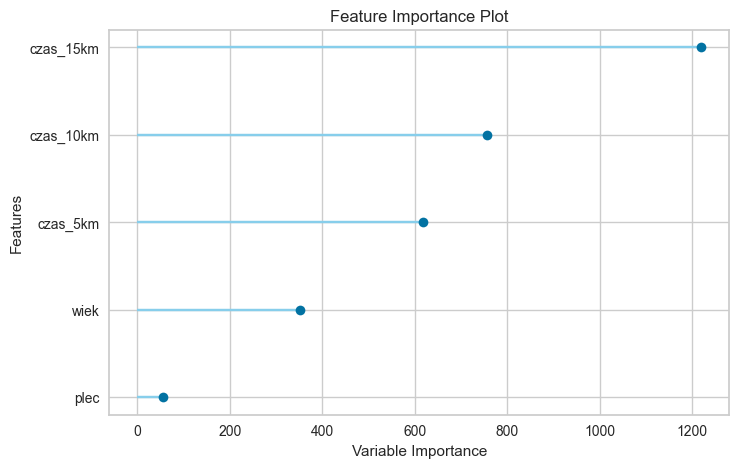

In [13]:
exp_all.plot_model(lgbm_all, plot="feature")

Najważniejsze na wykresie są czasy na 15 i 10 km, czas na 5 km jest zaraz za nimi, potem wiek, a płeć ma najmniejszy wpływ.
To logiczne - im bliżej mety, tym lepiej wiadomo, jaki będzie wynik (R2 w tabeli wyżej to prawie 0,99).
Ale w aplikacji użytkownik podaje tylko czas na 5 km, więc czasów na 10 i 15 km nie użyję.
Zostawiam: `plec`, `wiek`, `czas_5km`.

## 2.4 Trenuję model - flow z lekcji 24

In [14]:
# Eksperyment B - tylko cechy dostępne w aplikacji
exp = setup(
    data=clean_df,
    target="czas",
    ignore_features=["rok", "czas_10km", "czas_15km"],
    categorical_features=["plec"],
    numeric_features=["wiek", "czas_5km"],
    session_id=123,
    verbose=False,
)
exp.dataset_transformed.sample(5)

,plec,wiek,czas_5km,czas
15479,1.0,57.0,1721.0,7762.0
17033,1.0,53.0,1893.0,8367.0
6629,1.0,60.0,1711.0,8436.0
16748,0.0,25.0,1882.0,8235.0
14317,0.0,40.0,1600.0,7377.0


In [15]:
best_models = exp.compare_models(sort="MAE", n_select=3)

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
huber,Huber Regressor,256.6696,111830.2331,334.2872,0.9181,0.0432,0.0340,0.0650
gbr,Gradient Boosting Regressor,256.9053,110500.3752,332.3179,0.9191,0.0431,0.0342,0.1840
lr,Linear Regression,258.2294,110247.8122,331.9292,0.9193,0.0431,0.0344,0.0280
ridge,Ridge Regression,258.2294,110247.7863,331.9292,0.9193,0.0431,0.0344,0.0240
lar,Least Angle Regression,258.2294,110247.8122,331.9292,0.9193,0.0431,0.0344,0.0280
lasso,Lasso Regression,258.2606,110253.5565,331.9381,0.9193,0.0431,0.0344,0.0320
llar,Lasso Least Angle Regression,258.2606,110253.5568,331.9381,0.9193,0.0431,0.0344,0.0300
en,Elastic Net,258.3133,110262.9757,331.9533,0.9193,0.0431,0.0344,0.0610
br,Bayesian Ridge,258.3285,110293.1450,331.9974,0.9192,0.0431,0.0344,0.0290
omp,Orthogonal Matching Pursuit,258.8353,110718.6311,332.6380,0.9189,0.0432,0.0345,0.0280


In [16]:
# Tak jak w lekcji 24 - stroję najlepsze modele i porównuję je z wersjami bez strojenia
tuned_best_models = [exp.tune_model(m, optimize="MAE") for m in best_models]

,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,242.6285,102541.4811,320.2210,0.9198,0.0417,0.0324
1,253.7272,112268.1708,335.0644,0.9178,0.0433,0.0337
2,247.0477,101329.1232,318.3224,0.9159,0.0417,0.0331
3,261.9205,115160.3210,339.3528,0.9159,0.0434,0.0343
4,258.8460,118042.9000,343.5737,0.9228,0.0441,0.0341
5,256.9114,112207.4166,334.9738,0.9178,0.0439,0.0341
6,272.4568,126565.6896,355.7607,0.9102,0.0453,0.0354
7,259.3112,118067.4181,343.6094,0.9147,0.0442,0.0341
8,258.4783,114788.8195,338.8050,0.9184,0.0432,0.0339


Fitting 10 folds for each of 10 candidates, totalling 100 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,257.0926,116515.9978,341.3444,0.9088,0.0439,0.0343
1,272.4757,129545.9926,359.9250,0.9051,0.0462,0.0363
2,266.0081,119745.8296,346.0431,0.9006,0.0446,0.0355
3,275.5055,125557.1312,354.3404,0.9083,0.0454,0.0363
4,268.8137,126964.9896,356.3215,0.9170,0.0455,0.0355
5,268.7659,124547.7344,352.9132,0.9087,0.0457,0.0358
6,286.6738,138605.3708,372.2974,0.9017,0.0475,0.0376
7,272.8911,130879.3631,361.7725,0.9054,0.0463,0.0361
8,270.0999,126193.4997,355.2372,0.9103,0.0454,0.0357


Fitting 10 folds for each of 10 candidates, totalling 100 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,245.1787,99855.2764,315.9989,0.9219,0.0415,0.0330
1,258.3123,110926.1018,333.0557,0.9187,0.0434,0.0346
2,251.2162,100477.1238,316.9813,0.9166,0.0417,0.0339
3,260.3538,110043.8958,331.7286,0.9197,0.0429,0.0344
4,262.3506,116579.5499,341.4375,0.9237,0.0440,0.0348
5,259.1893,109888.2268,331.4939,0.9195,0.0435,0.0346
6,268.0981,116856.0778,341.8422,0.9171,0.0440,0.0353
7,258.2059,112337.4598,335.1678,0.9188,0.0435,0.0343
8,260.4160,113021.6097,336.1869,0.9197,0.0432,0.0345


Fitting 10 folds for each of 2 candidates, totalling 20 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


In [17]:
best_model = exp.compare_models(best_models + tuned_best_models, sort="MAE")
best_model

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
0,Huber Regressor,256.6696,111830.2331,334.2872,0.9181,0.0432,0.0340,0.0540
3,Huber Regressor,256.6696,111830.2331,334.2872,0.9181,0.0432,0.0340,0.0410
1,Gradient Boosting Regressor,256.9053,110500.3752,332.3179,0.9191,0.0431,0.0342,0.1840
4,Gradient Boosting Regressor,256.9053,110500.3752,332.3179,0.9191,0.0431,0.0342,0.1720
2,Linear Regression,258.2294,110247.8122,331.9292,0.9193,0.0431,0.0344,0.0190
5,Linear Regression,258.2294,110247.8122,331.9292,0.9193,0.0431,0.0344,0.0210


HuberRegressor()

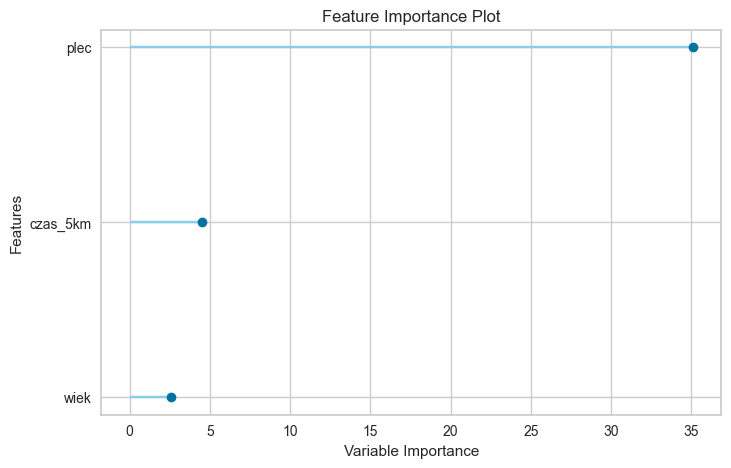

In [18]:
exp.plot_model(best_model, plot="feature")

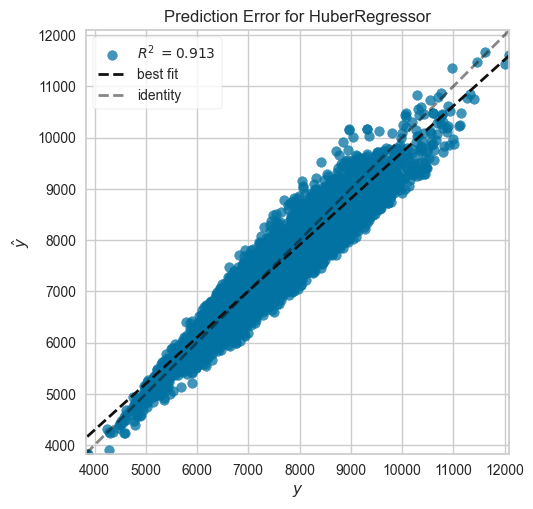

In [19]:
exp.plot_model(best_model, plot="error")

In [20]:
# Metryki na zbiorze testowym (holdout) - zapisuję je razem z modelem
exp.predict_model(best_model)
holdout_metrics = exp.pull()
holdout_metrics

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE
0,Huber Regressor,264.5342,118343.5456,344.0110,0.9132,0.0443,0.0350


,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE
0,Huber Regressor,264.5342,118343.5456,344.011,0.9132,0.0443,0.035


In [21]:
best_final_model = exp.finalize_model(best_model)
best_final_model

Pipeline(memory=Memory(location=None),
         steps=[('numerical_imputer',
                 TransformerWrapper(include=['wiek', 'czas_5km'],
                                    transformer=SimpleImputer())),
                ('categorical_imputer',
                 TransformerWrapper(include=['plec'],
                                    transformer=SimpleImputer(strategy='most_frequent'))),
                ('ordinal_encoding',
                 TransformerWrapper(include=['plec'],
                                    transformer=OrdinalEncoder(cols=['plec'],
                                                               handle_missing='return_nan',
                                                               mapping=[{'col': 'plec',
                                                                         'data_type': dtype('O'),
                                                                         'mapping': K      0
M      1
NaN   -1
dtype: int64}]))),
                ('actual_estimator', HuberRegressor())])

## 2.5 Zapisuję nową wersję modelu lokalnie i do Digital Ocean Spaces

Każdy przebieg pipeline'u zapisuje nową wersję z datą w nazwie, a dodatkowo kopię jako `latest`,
z której korzysta aplikacja. Obok modelu zapisuję plik JSON z metrykami.

*Dodatek: wersjonowanie datą, kopia `latest` i plik JSON z metrykami to moje rozwiązanie - w kursie model zapisywałem pod jedną nazwą.*

In [22]:
LOCAL_MODELS_PATH.mkdir(exist_ok=True)

version = datetime.now().strftime("%Y%m%d_%H%M%S")
model_name = f"model_polmaraton_{version}"

# save_model z lekcji 24 - PyCaret sam dokleja rozszerzenie .pkl
exp.save_model(best_final_model, str(LOCAL_MODELS_PATH / model_name), verbose=False)

metrics = holdout_metrics.drop(columns=["Model"]).to_dict(orient="records")[0]
metrics["model"] = holdout_metrics["Model"].values[0]
metrics["version"] = version
metrics["features"] = ["plec", "wiek", "czas_5km"]
with open(LOCAL_MODELS_PATH / f"{model_name}.json", "w", encoding="utf-8") as f:
    f.write(json.dumps(metrics, ensure_ascii=False, indent=2))

# Kopia jako "latest" - z niej korzysta aplikacja
shutil.copy(LOCAL_MODELS_PATH / f"{model_name}.pkl", LOCAL_MODELS_PATH / "model_polmaraton_latest.pkl")
shutil.copy(LOCAL_MODELS_PATH / f"{model_name}.json", LOCAL_MODELS_PATH / "model_polmaraton_latest.json")

metrics

{'MAE': 264.5342,
 'MSE': 118343.5456,
 'RMSE': 344.011,
 'R2': 0.9132,
 'RMSLE': 0.0443,
 'MAPE': 0.035,
 'model': 'Huber Regressor',
 'version': '20261019_133436',
 'features': ['plec', 'wiek', 'czas_5km']}

In [23]:
# Wysyłam pliki do Spaces - upload_file z lekcji 10
s3 = boto3.client("s3")

for file_name in [
    f"{model_name}.pkl",
    f"{model_name}.json",
    "model_polmaraton_latest.pkl",
    "model_polmaraton_latest.json",
]:
    s3_path = f"{MODELS_PREFIX}{file_name}"
    print(f"Wysyłam plik {file_name} do {s3_path}")
    s3.upload_file(
        Filename=str(LOCAL_MODELS_PATH / file_name),
        Bucket=BUCKET_NAME,
        Key=s3_path,
    )

Wysyłam plik model_polmaraton_20261019_133436.pkl do polmaraton/models/model_polmaraton_20261019_133436.pkl
Wysyłam plik model_polmaraton_20261019_133436.json do polmaraton/models/model_polmaraton_20261019_133436.json
Wysyłam plik model_polmaraton_latest.pkl do polmaraton/models/model_polmaraton_latest.pkl
Wysyłam plik model_polmaraton_latest.json do polmaraton/models/model_polmaraton_latest.json


In [24]:
# Sprawdzam wszystkie wersje modelu w Spaces
response = s3.list_objects_v2(Bucket=BUCKET_NAME, Prefix=MODELS_PREFIX)
for obj in response["Contents"]:
    print(obj["Key"], obj["LastModified"])

polmaraton/models/model_polmaraton_20261019_132955.json 2026-10-19 11:29:58.032000+00:00
polmaraton/models/model_polmaraton_20261019_132955.pkl 2026-10-19 11:29:57.945000+00:00
polmaraton/models/model_polmaraton_20261019_133436.json 2026-10-19 11:34:38.573000+00:00
polmaraton/models/model_polmaraton_20261019_133436.pkl 2026-10-19 11:34:38.473000+00:00
polmaraton/models/model_polmaraton_latest.json 2026-10-19 11:34:38.763000+00:00
polmaraton/models/model_polmaraton_latest.pkl 2026-10-19 11:34:38.677000+00:00


In [25]:
# Szybki test zapisanego modelu - tak jak w lekcji 29 podaję dane w słowniku
from pycaret.regression import load_model, predict_model

loaded_model = load_model(str(LOCAL_MODELS_PATH / "model_polmaraton_latest"))
input_data = {
    "plec": "M",
    "wiek": 35,
    "czas_5km": 25 * 60,
}
prediction = predict_model(loaded_model, data=pd.DataFrame([input_data]))["prediction_label"].iloc[0]
print(f"Szacowany czas: {int(prediction // 3600)}:{int(prediction % 3600 // 60):02d}:{int(prediction % 60):02d}")

Transformation Pipeline and Model Successfully Loaded


Szacowany czas: 1:49:16
